# Numbers for the beta-NLL sweep -- the Gaussian lambdas of `pr_classic1`

Counterpart of the canal 1 reporting notebooks, **same output tree**, but the swept axis changes: there the models were filtered on `lambda_keep=0.0` and compared across families; here we keep **the whole lambda sweep** (`lambda_keep=None`) and compare **one Gaussian head to itself** across beta.

`lambda` in the config *is* the beta-NLL exponent (Seitzer et al. 2022): `loss = stopgrad(var)^beta * [(y-mu)^2/(2 var) + log var / 2]`.

- **beta = 0** is exactly the proper Gaussian NLL -- it is the **reference** for every difference below.
- **beta = 1** is the improper end, a variance-weighted MSE, meant to fix the gradient starvation of the heteroscedastic NLL (at points where the network predicts a large variance, the mean's gradient is artificially reduced).

Only the three Gaussian heads have `uses_lam=True`; the count models and `msemeanonly` have no lambda axis and are out of scope here.

**The three heads form a gradation of the grain at which beta acts**, and that is what gives the sweep its structure. The mechanism beta-NLL fixes requires the variance to vary **across examples**: heteroscedastic, it varies per (spot, gene); spot-homoscedastic, per spot; gene-homoscedastic, not at all, no spot can be reweighted relative to another.

**`homoscedastic` is not a control.** The weight `sigma_g^(2 beta)` is constant *per gene*, so it does not come out of the sum: it reweights the **genes against each other** through the shared trunk, from `1/sigma_g^2` at beta = 0 toward uniform at beta = 1. At finite capacity this changes the gradient direction. The invariance would hold only for a single output or for per-gene independent trunks. What the corresponding cell measures is therefore whether this **inter-gene channel** produces anything -- a result, not a check.

What the notebook produces: the absolute levels per (head, beta), the donor-paired differences against beta = 0 with the three uncertainty readings, the inter-gene channel measurement, a figure, and the explicit answer to the two questions this sweep was originally launched to settle.

In [1]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)

# benchmark_summary.py is edited alongside this notebook, and a kernel that already imported it
# keeps the module object cached, so a new function would stay invisible and raise NameError.
import src.evaluation.benchmark_summary as bs
importlib.reload(bs)
from src.evaluation.benchmark_summary import (
    discover_run_summaries, headline_registry, format_headline_registry,
    paired_deltas_full, donor_lopo_stats,
)

# SAME run and SAME output tree as the canal 1 reporting notebooks -- only the filtering differs.
RUN_ID    = "pr_classic1"
DATASETS  = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS    = "r75"
NS        = [50, 100, 500, 1000, 2000, None]   # None -> the full shared panel

# The beta-NLL sweep axis lives ONLY on the three Gaussian heads (uses_lam=True). The count models
# and msemeanonly have no lambda_ path segment at all, so they are out of scope here: this notebook
# compares a head to ITSELF across beta, never one head to another.
GAUSS     = ["homoscedastic", "heteroscedastic", "spot_homoscedastic"]
BASE_BETA = 0.0            # beta = 0 IS the proper Gaussian NLL: the reference for every delta below

# beta trades the MEAN fit against a proper likelihood, so both sides must be read together, and
# "better" is NOT the same direction for all five: two are signed, where better means closer to 0.
METRICS = ("pearson", "ece_pit", "pit_bias", "disp_signed", "var_residual_corr")
BETTER  = {"pearson": "higher", "var_residual_corr": "higher", "ece_pit": "lower",
           "pit_bias": "close to 0 (signed)", "disp_signed": "close to 0 (signed)"}

def _mt(label):    return label.split("|")[0]                      # 'heteroscedastic|lam0.5' -> head
def _beta(label):  return float(label.split("|lam")[1]) if "|lam" in label else float("nan")

# lambda_keep=None keeps the WHOLE sweep; the reporting notebooks pass 0.0 and keep only the proper NLL.
summaries = discover_run_summaries(PROJ / "results", RUN_ID, DATASETS,
                                   radius=RADIUS, models=GAUSS, lambda_keep=None)

# The betas are DISCOVERED from what is on disk, never hardcoded: the run directory is the
# authority, and a hardcoded grid would silently hide a missing or an unexpected run.
BETAS = sorted({_beta(s["label"]) for s in summaries})
print(f"{len(summaries)} runs loaded   betas found: {BETAS}")
if not summaries:
    print("\n  NO run. discover_run_summaries reads benchmark_summary.parquet, written by canal1\n"
          "  (snake/scripts/canals/canal1_benchmark_summary_precompute.py). Run canal1 on\n"
          "  pr_classic1 before this notebook.")

for ds in DATASETS:
    for mt in GAUSS:
        got = sorted(_beta(s["label"]) for s in summaries
                     if s["dataset"] == ds and _mt(s["label"]) == mt)
        missing = sorted(set(BETAS) - set(got))
        print(f"   {ds:<12s} {mt:<20s} betas {got}"
              + (f"   <-- INCOMPLETE, missing {missing}" if missing else ""))

45 runs loaded   betas found: [0.0, 0.25, 0.5, 0.75, 1.0]
   10x_TuPro    homoscedastic        betas [0.0, 0.25, 0.5, 0.75, 1.0]
   10x_TuPro    heteroscedastic      betas [0.0, 0.25, 0.5, 0.75, 1.0]
   10x_TuPro    spot_homoscedastic   betas [0.0, 0.25, 0.5, 0.75, 1.0]
   TLS          homoscedastic        betas [0.0, 0.25, 0.5, 0.75, 1.0]
   TLS          heteroscedastic      betas [0.0, 0.25, 0.5, 0.75, 1.0]
   TLS          spot_homoscedastic   betas [0.0, 0.25, 0.5, 0.75, 1.0]
   LUNG_CANCER  homoscedastic        betas [0.0, 0.25, 0.5, 0.75, 1.0]
   LUNG_CANCER  heteroscedastic      betas [0.0, 0.25, 0.5, 0.75, 1.0]
   LUNG_CANCER  spot_homoscedastic   betas [0.0, 0.25, 0.5, 0.75, 1.0]


In [2]:
# ABSOLUTE levels on the full gene panel. No top-n cutoff here, and that is the point: a
# cumulative curve ranks the genes with the very metric it then reports, whereas the full
# panel is selected by nothing. These are therefore the honest numbers to cite.
stats_headline, donor_points = headline_registry(summaries, metrics=METRICS)

# format_headline_registry sorts the models by DECREASING value, which means "best first" only
# for pearson and var_residual_corr. For ece_pit and the two signed metrics, read the pivots
# below and not the row order.
print(format_headline_registry(stats_headline, datasets=DATASETS, metrics=("pearson",)))

for m in METRICS:
    print(f"\n{'=' * 96}\n{m}   (better = {BETTER[m]})   mean over donors +/- Student-t half-CI\n{'=' * 96}")
    for ds in DATASETS:
        sub = donor_points[(donor_points["dataset"] == ds) & (donor_points["metric"] == m)]
        if sub.empty:
            continue
        cells = {}
        for model, g in sub.groupby("model"):
            st = donor_lopo_stats(dict(zip(g["donor"], g["value"])))
            hw = (st["ci95_mean"][1] - st["ci95_mean"][0]) / 2
            cells[(_mt(model), _beta(model))] = f"{st['mean']:+.4f}+/-{hw:.4f}"
        print(f"\n-- {ds} --")
        print(pd.Series(cells).unstack().reindex(index=GAUSS, columns=BETAS).to_string())

HEADLINE -- full shared gene panel. THREE DIFFERENT THINGS, do not swap them:
  SE / t-CI     spread of the MEAN over donors (patients resampled, gene panel fixed).
                One estimand, two presentations: t-CI = mean +/- t*·SE.  <- THE headline bar.
  PI-new-donor  where a NEW patient would land. Wider, and a different question entirely.
  gene-boot     genes resampled, donor cohort FIXED -> ZERO inter-donor variance.
                Gene-panel stability only; far narrower (N genes vs K donors).
LOPO folds share K-2 training donors (Bengio & Grandvalet 2004), so these intervals are
optimistic -- always read them next to the per-donor points (donor_points).

--- 10x_TuPro | pearson  (K=7 donors, N=3000 genes) ---
  spot_homoscedastic|lam0.25                 +0.1770  SE 0.0131  t-CI [+0.1450,+0.2091] (df 6, t* 2.45)  PI-new-donor [+0.0865,+0.2676]  gene-boot [+0.1722,+0.1816] (SE 0.0025)
  spot_homoscedastic|lam0.0                  +0.1752  SE 0.0134  t-CI [+0.1425,+0.2079] (df 

In [3]:
# Beta's effect is read WITHIN a head, against its own beta = 0: same architecture, same donor,
# same genes, only the loss changes. The difference is taken donor by donor, so the donor effect
# -- which dominates the raw spread and is IDENTICAL for both terms -- cancels exactly, and the
# interval is ~10x tighter than on the absolute levels of the previous cell.
#
# paired_deltas_full accepts only ONE reference per (dataset, gene_set) group. So it is called one
# time PER HEAD, on that head's summaries only; calling it once on the whole sweep would also
# compare spot_homoscedastic|lam0.5 to homoscedastic|lam0.0, which makes no sense.
parts = []
for mt in GAUSS:
    fam = [s for s in summaries if _mt(s["label"]) == mt]
    ref = f"{mt}|lam{BASE_BETA}"
    if not any(s["label"] == ref for s in fam):
        print(f"   (!) {mt} : reference {ref} absent -- head skipped")
        continue
    d = paired_deltas_full(fam, reference=ref, metrics=METRICS, ns=NS)
    parts.append(d.assign(head=mt, beta=d["model"].map(_beta)))

beta_deltas = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
NMAX = int(beta_deltas["n"].max())
print(f"{len(beta_deltas)} deltas (dataset x head x beta x metric x cutoff), full panel = {NMAX}")

for m in METRICS:
    print(f"\n{'=' * 132}\nDelta vs beta = {BASE_BETA}  --  {m}   (better = {BETTER[m]})")
    print("  each cell: delta, then '*' if the Student-t donor CI excludes 0 (what matters: a")
    print("  NEW patient), 'o' if the gene-bootstrap CI excludes 0 (gene panel stability,")
    print("  donor cohort FIXED), then the HALF-WIDTH of the donor CI. So the CI is")
    print("  delta +/- that half-width, and the '*' can be re-read by eye: |delta| > half-width.")
    print("=" * 132)
    for ds in DATASETS:
        sub = beta_deltas[(beta_deltas["dataset"] == ds) & (beta_deltas["metric"] == m)]
        if sub.empty:
            continue
        print(f"\n-- {ds} --")
        # The beta = 0 level is SPECIFIC TO EACH HEAD (each is compared to its own reference),
        # so it groups by head. Taking it by cutoff only would show one head's reference for
        # all three, which is wrong and misleading.
        for head, g in sub.groupby("head"):
            base = g.drop_duplicates("n").set_index("n")["reference_mean"]
            print(f"   base beta=0  {head:<20s} "
                  + "  ".join(f"n={int(n_cut)}: {v:+.4f}" for n_cut, v in base.items()))
        cells = [f"{r.delta_mean:+.4f}{'*' if r.excludes_zero_t else ' '}"
                 f"{'o' if r.excludes_zero_gene else ' '} "
                 f"+/-{(r.delta_ci_hi - r.delta_ci_lo) / 2:.4f}" for r in sub.itertuples()]
        k = sub["head"] + "  beta=" + sub["beta"].astype(str)
        print(sub.assign(c=cells, k=k).pivot_table(index="k", columns="n",
                                                   values="c", aggfunc="first").to_string())

# The three half-widths side by side, at the full panel: t-CI / 1 SEM / gene-boot. The first is
# already in the table above; this block adds the other two, which describe the SAME point
# quantity and differ only by what is resampled (donors for the first two, genes for the third,
# at a frozen donor cohort).
print(f"\n{'=' * 132}\nhalf-widths at the full panel (n = {NMAX})  --  t-CI / SEM / gene-boot\n{'=' * 132}")
for m in METRICS:
    sub = beta_deltas[(beta_deltas["metric"] == m) & (beta_deltas["n"] == NMAX)]
    if sub.empty:
        continue
    w = [f"{(r.delta_ci_hi - r.delta_ci_lo) / 2:.4f}/{r.delta_sem:.4f}/"
         f"{(r.gene_ci_hi - r.gene_ci_lo) / 2:.4f}" for r in sub.itertuples()]
    print(f"\n-- {m} --")
    print(sub.assign(c=w, k=sub["head"] + "  beta=" + sub["beta"].astype(str))
          .pivot_table(index="k", columns="dataset", values="c", aggfunc="first")
          .reindex(columns=DATASETS).to_string())

1080 deltas (dataset x head x beta x metric x cutoff), full panel = 3000

Delta vs beta = 0.0  --  pearson   (better = higher)
  each cell: delta, then '*' if the Student-t donor CI excludes 0 (what matters: a
  NEW patient), 'o' if the gene-bootstrap CI excludes 0 (gene panel stability,
  donor cohort FIXED), then the HALF-WIDTH of the donor CI. So the CI is
  delta +/- that half-width, and the '*' can be re-read by eye: |delta| > half-width.

-- 10x_TuPro --
   base beta=0  heteroscedastic      n=50: +0.5466  n=100: +0.5084  n=500: +0.3905  n=1000: +0.3270  n=2000: +0.2424  n=3000: +0.1730
   base beta=0  homoscedastic        n=50: +0.5461  n=100: +0.5076  n=500: +0.3907  n=1000: +0.3269  n=2000: +0.2427  n=3000: +0.1734
   base beta=0  spot_homoscedastic   n=50: +0.5519  n=100: +0.5117  n=500: +0.3932  n=1000: +0.3298  n=2000: +0.2449  n=3000: +0.1752
n                                             50                   100                  500                  1000                 200

In [4]:
# THE INTER-GENE REWEIGHTING CHANNEL. This is NOT a control: the
# invariance holds only for a ONE-output model, or for per-gene independent trunks.
#
# The beta-NLL weight is sigma^(2*beta). On the gene-homoscedastic head, sigma_g is constant OVER
# THE SPOTS of a gene, so the weight is constant PER GENE -- but not over the whole summed index.
# It therefore does not come out of the sum, and the gradient on the SHARED trunk is
#
#     grad_phi L_beta = sum_g sigma_g^(2*beta - 2) * sum_s (mu_sg - y_sg) * grad_phi mu_sg
#
# beta = 0 weights each gene by 1/sigma_g^2 (the low-noise genes dominate), beta = 1 gives an MSE
# uniform across genes. At finite capacity with a shared trunk, this changes the DIRECTION of the
# gradient, not only its norm. Only independent trunks would split the problem into G subproblems
# homoscedastic, each genuinely invariant.
#
# What stays true and structures the sweep: the mechanism beta-NLL fixes (gradient starvation)
# requires sigma to vary ACROSS EXAMPLES. The three heads form a gradation of that grain --
# heteroscedastic per (spot, gene), spot-homoscedastic per spot, gene-homoscedastic not at all.
# This head is therefore the only one where beta acts ONLY through the inter-gene channel, and this
# block measures whether that channel produces anything detectable. It is a RESULT, not a check.
#
# Two caveats before concluding:
#   1. each beta is a SEPARATE training run (same seed, its own trajectory), so a non-zero gap is
#      expected; the question is not "is it zero" but "is it detected".
#   2. at 95%, a handful of detections over several dozen comparisons is the nominal false-positive
#      rate. What we look for is a systematic pattern, not an isolated point.
#
# var_residual_corr is undefined for THIS head, and for it alone: its predicted variance is a
# per-gene constant, so inside a (slide, gene) atom the predictor does not vary and its
# correlation with the residual does not exist -- every atom is NaN. It is dropped from the count
# rather than counted as "not detected", which would inflate the denominator by 20%.
h_all = beta_deltas[beta_deltas["head"] == "homoscedastic"]
h = h_all[h_all["delta_mean"].notna()]
n_det = int(h["excludes_zero_t"].sum())
print(f"homoscedastic : {n_det} / {len(h)} deltas whose donor CI excludes 0 "
      f"({100 * n_det / max(len(h), 1):.1f} %, against the ~5 % of false positives expected)")
print(f"                {len(h_all) - len(h)} deltas dropped, metric undefined for this head\n")

for m in METRICS:
    sub = h[h["metric"] == m]
    if sub.empty:
        print(f"  {m:<22s} undefined here (per-gene constant variance) -- dropped from the count")
        continue
    w = sub.loc[sub["delta_mean"].abs().idxmax()]
    # reference scale: is the largest gap large COMPARED TO the absolute level?
    scale = abs(sub["reference_mean"]).max()
    pct = 100 * abs(w["delta_mean"]) / scale if scale else float("nan")
    print(f"  {m:<22s} |delta| max = {abs(w['delta_mean']):.4f}  "
          f"({w['dataset']}, beta={w['beta']}, n={int(w['n'])})   "
          f"i.e. {pct:.1f} % of the level   "
          f"detected {int(sub['excludes_zero_t'].sum())}/{len(sub)}")

if n_det:
    print("\n  the detections, spelled out (compare with the pattern of the other two heads):")
    for r in h[h["excludes_zero_t"]].sort_values(["metric", "dataset", "n"]).itertuples():
        print(f"    {r.dataset:<12s} {r.metric:<22s} beta={r.beta:<5} n={int(r.n):<5d} "
              f"{r.delta_mean:+.4f} [{r.delta_ci_lo:+.4f},{r.delta_ci_hi:+.4f}]")
else:
    print("\n  no detection: the inter-gene channel produces nothing measurable here.")

homoscedastic : 2 / 288 deltas whose donor CI excludes 0 (0.7 %, against the ~5 % of false positives expected)
                72 deltas dropped, metric undefined for this head

  pearson                |delta| max = 0.0124  (10x_TuPro, beta=1.0, n=50)   i.e. 2.3 % of the level   detected 2/72
  ece_pit                |delta| max = 0.0069  (10x_TuPro, beta=1.0, n=50)   i.e. 3.2 % of the level   detected 0/72
  pit_bias               |delta| max = 0.0089  (LUNG_CANCER, beta=1.0, n=50)   i.e. 23.4 % of the level   detected 0/72
  disp_signed            |delta| max = 0.0236  (10x_TuPro, beta=1.0, n=50)   i.e. 16.0 % of the level   detected 0/72
  var_residual_corr      undefined here (per-gene constant variance) -- dropped from the count

  the detections, spelled out (compare with the pattern of the other two heads):
    10x_TuPro    pearson                beta=0.25  n=50    +0.0097 [+0.0031,+0.0163]
    10x_TuPro    pearson                beta=0.25  n=100   +0.0077 [+0.0016,+0.0138]


/scratch/slurm-job.9530782/ipykernel_572435/384292817.py:55: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  det = d["excludes_zero_t"].fillna(False).to_numpy().astype(bool)
/scratch/slurm-job.9530782/ipykernel_572435/384292817.py:55: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  det = d["excludes_zero_t"].fillna(False).to_numpy().astype(bool)
/scratch/slurm-job.9530782/ipykernel_572435/384292817.py:55: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy

written: fig_beta_nll_sweep.pdf


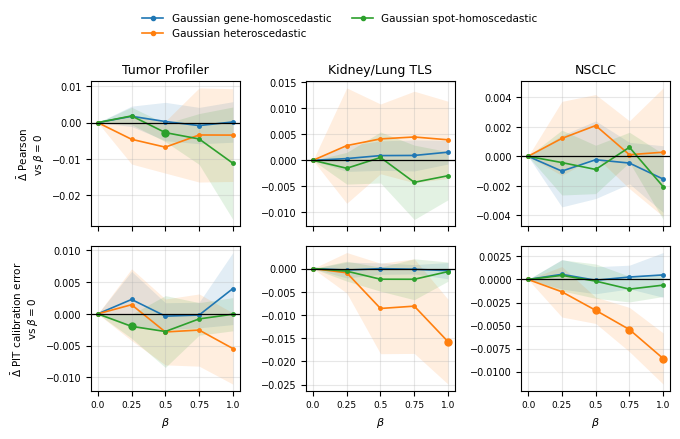

In [5]:
# FIGURE fig:beta-nll-sweep -- 2 metrics x 3 datasets, x = beta.
# We plot the PAIRED DIFFERENCE against beta = 0, not the absolute level, for the same reason as
# the mean-performance figure: beta's effect is small next to the inter-donor spread, so on the
# absolute levels the curves overlap and nothing is readable. Here the zero line IS the proper
# NLL. The absolute levels live in the headline cell.
#
# Two rows: the mean (what beta is supposed to improve) and the MAGNITUDE of the calibration error.
# Both are legitimately read as a delta, because "better" is a fixed direction there (pearson
# higher, ece_pit lower): a delta alone is enough to decide.
#
# disp_signed (the SIGN of the mis-calibration, over/under-confidence) is deliberately ABSENT from
# the figure: it is a SIGNED metric where "better" means closer to zero, so a delta against
# beta = 0 does not say which side of zero we start from -- the same positive delta can fix an
# under-confidence or deepen an over-confidence. It only makes sense as an ABSOLUTE LEVEL, and
# that is where it is reported: headline cell, and Q2 of the answers cell.
#
# SIZED FOR A PORTRAIT PAGE, at its printed size (~6.9 in for a textwidth of ~6.3 in): a wide
# figure shrunk by \includegraphics[width=\textwidth] gets its fonts shrunk by the same factor.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Colors aligned with the canonical model color map, so each head keeps ONE color everywhere
# (canonical map, copied rather than re-picked).
HEAD_COLORS = {"homoscedastic": "#1f77b4", "heteroscedastic": "#ff7f0e",
               "spot_homoscedastic": "#2ca02c"}
# The gene-homoscedastic head's label states the grain at which beta acts, NOT "control": beta
# reweights no spot there, but it still reweights the genes against each other via the shared
# trunk, so the invariance is not guaranteed (see the inter-gene channel cell).
HEAD_LABELS = {"homoscedastic": "Gaussian gene-homoscedastic",# (no per-spot reweighting)",
               "heteroscedastic": "Gaussian heteroscedastic",
               "spot_homoscedastic": "Gaussian spot-homoscedastic"}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung TLS", "LUNG_CANCER": "NSCLC"}
ROWS = [("pearson", "Pearson"), ("ece_pit", "PIT calibration error")]

x = np.arange(len(BETAS))
fig, axes = plt.subplots(len(ROWS), len(DATASETS), figsize=(6.9, 4.4), sharex=True)

for i, (m, ylab) in enumerate(ROWS):
    for j, ds in enumerate(DATASETS):
        ax = axes[i, j]
        for head in GAUSS:
            d = beta_deltas[(beta_deltas["dataset"] == ds) & (beta_deltas["metric"] == m)
                            & (beta_deltas["head"] == head) & (beta_deltas["n"] == NMAX)]
            if d.empty:
                continue
            # beta = 0 is the reference: paired_deltas_full does not emit it, we put it back at 0
            # -- that is its exact value by construction, not an imputation.
            d = d.set_index("beta").reindex(BETAS)
            mean = d["delta_mean"].fillna(0.0).to_numpy()
            lo = d["delta_ci_lo"].fillna(0.0).to_numpy()
            hi = d["delta_ci_hi"].fillna(0.0).to_numpy()
            c = HEAD_COLORS[head]
            ax.fill_between(x, lo, hi, color=c, alpha=0.13, linewidth=0)
            ax.plot(x, mean, "-o", ms=2.5, lw=1.2, color=c)
            det = d["excludes_zero_t"].fillna(False).to_numpy().astype(bool)
            ax.plot(x[det], mean[det], "o", ms=5, color=c, zorder=5)   # donor CI excluding 0
        ax.axhline(0, color="black", lw=0.9)
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=7)
        if i == 0:
            ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
        if i == len(ROWS) - 1:
            ax.set_xticks(x)
            ax.set_xticklabels([str(b) for b in BETAS], fontsize=6.5)
            ax.set_xlabel(r"$\beta$", fontsize=8)
    axes[i, 0].set_ylabel(f"$\\bar{{\\Delta}}$ {ylab}\nvs $\\beta = 0$", fontsize=7.5)

handles = [Line2D([0], [0], color=HEAD_COLORS[h], marker="o", ms=3, lw=1.2, label=HEAD_LABELS[h])
           for h in GAUSS]
# the strip reserved for the legend keeps the SAME absolute height (~0.43 in) as at three rows, so
# the fraction changes with the figure: 1 - 0.43/4.4 ~= 0.90.
plt.tight_layout(rect=[0, 0, 1, 0.90])
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=2,
           frameon=False, fontsize=7.5)

FIG_DIR = PROJ / "results" / "_analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"fig_beta_nll_sweep.{ext}", dpi=300, bbox_inches="tight")
print("written:", "fig_beta_nll_sweep.pdf")
plt.show()

In [6]:
# The two questions this sweep was originally launched to settle,
# answered at the full panel, head by head and dataset by dataset.
#
# Q1 is read on the PAIRED DELTA (pearson: higher = better, so a positive delta is enough).
# Q2 must be read on the ABSOLUTE LEVELS: pit_bias and disp_signed are SIGNED, "better" means
# closer to zero, and a delta alone does not say which side of zero we start from -- a positive
# delta can just as well fix an under-confidence as create an over-confidence.
lvl = {}
for (ds, model, m), g in donor_points.groupby(["dataset", "model", "metric"]):
    lvl[(ds, _mt(model), _beta(model), m)] = float(g["value"].astype(float).mean())

print("Q1  does beta improve the mean correlation (the benefit beta-NLL is supposed to bring)?")
print("    paired delta vs beta = 0, full panel; '*' = Student-t donor CI excluding 0\n")
for ds in DATASETS:
    for head in GAUSS:
        d = beta_deltas[(beta_deltas["dataset"] == ds) & (beta_deltas["head"] == head)
                        & (beta_deltas["metric"] == "pearson") & (beta_deltas["n"] == NMAX)]
        if d.empty:
            continue
        cells = "  ".join(f"b={r.beta}: {r.delta_mean:+.4f}{'*' if r.excludes_zero_t else ' '}"
                          for r in d.sort_values("beta").itertuples())
        best = d.loc[d["delta_mean"].idxmax()]
        verdict = (f"best b={best['beta']} ({best['delta_mean']:+.4f}"
                   f"{', detected' if best['excludes_zero_t'] else ', NOT detected'})")
        print(f"  {DATASET_LABELS.get(ds, ds):<17s} {head:<20s} "
              f"base {lvl[(ds, head, BASE_BETA, 'pearson')]:+.4f}   {cells}   -> {verdict}")

print("\n\nQ2  does beta bring the calibration closer to zero?")
print("    ABSOLUTE levels at the full panel (see the comment above: the signed metrics")
print("    cannot be read on a delta)\n")
for m in ("ece_pit", "pit_bias", "disp_signed"):
    print(f"  -- {m}   (better = {BETTER[m]}) --")
    for ds in DATASETS:
        for head in GAUSS:
            vals = [(b, lvl[(ds, head, b, m)]) for b in BETAS if (ds, head, b, m) in lvl]
            if not vals:
                continue
            # ece_pit is a magnitude (minimize the value); the other two are signed
            # (minimize the ABSOLUTE value, since moving away from zero the other way is as bad)
            key = (lambda bv: bv[1]) if m == "ece_pit" else (lambda bv: abs(bv[1]))
            b_best = min(vals, key=key)[0]
            moved = "yes" if b_best != BASE_BETA else "no, beta = 0 stays the best"
            print(f"    {DATASET_LABELS.get(ds, ds):<17s} {head:<20s} "
                  + "  ".join(f"b={b}: {v:+.4f}" for b, v in vals)
                  + f"   -> optimum b={b_best} ({moved})")
    print()

Q1  does beta improve the mean correlation (the benefit beta-NLL is supposed to bring)?
    paired delta vs beta = 0, full panel; '*' = Student-t donor CI excluding 0

  Tumor Profiler    homoscedastic        base +0.1734   b=0.25: +0.0017   b=0.5: +0.0003   b=0.75: -0.0008   b=1.0: +0.0002    -> best b=0.25 (+0.0017, NOT detected)
  Tumor Profiler    heteroscedastic      base +0.1730   b=0.25: -0.0046   b=0.5: -0.0068   b=0.75: -0.0034   b=1.0: -0.0034    -> best b=0.75 (-0.0034, NOT detected)
  Tumor Profiler    spot_homoscedastic   base +0.1752   b=0.25: +0.0018   b=0.5: -0.0028*  b=0.75: -0.0045   b=1.0: -0.0112    -> best b=0.25 (+0.0018, NOT detected)
  Kidney/Lung TLS   homoscedastic        base +0.0451   b=0.25: +0.0003   b=0.5: +0.0009   b=0.75: +0.0009   b=1.0: +0.0016    -> best b=1.0 (+0.0016, NOT detected)
  Kidney/Lung TLS   heteroscedastic      base +0.0401   b=0.25: +0.0028   b=0.5: +0.0041   b=0.75: +0.0045   b=1.0: +0.0039    -> best b=0.75 (+0.0045, NOT detected)
  K